In [10]:
from pathlib import Path
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import load_model
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score
from tensorflow.keras.models import load_model

PUBLIC_DATAPATH = Path("C:/Users/magol/peach-leaf-classification/data/public_dataset/public_data") 
LOCAL_DATAPATH = Path("C:/Users/magol/peach-leaf-classification/data/merged_dataset/local_data") 

BASE_SEED = 5681
TEST_SIZE = 0.2

OUTPUT_DIR = Path("../visualizations")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


BATCH_SIZE = 16

# CSVs 
base_models_csv = Path("./base_models_results/holdout_test_metrics_all_models.csv") 
cbam_models_csv = Path("./cbam_models_results/holdout_test_metrics_all_models.csv") 
tl_base_models_csv = Path("./tl_base_models_results/domain_shift_tl_results.csv") 
tl_cbam_models_csv = Path("./tl_cbam_models_results/domain_shift_cbam_tl_results.csv") 

# esto irlo cambiando según el CSV que quieras analizar
csv_data = base_models_csv


BASE_MODELS_PATH = Path("./models/Base/final_model") 
CBAM_MODELS_PATH = Path("./models/CBAM/final_model") 
TL_BASE_MODELS_PATH = Path("./models/Base_tl/final_model") 
TL_CBAM_MODELS_PATH = Path("./models/CBAM_tl/final_model") 

OUTPUT_DIR = Path("./visualizations")
MODEL_SPECS = {
    "mobilenetv2": (
        tf.keras.applications.MobileNetV2,
        tf.keras.applications.mobilenet_v2.preprocess_input,
    ),
    "efficientnetb0": (
        tf.keras.applications.EfficientNetB0,
        tf.keras.applications.efficientnet.preprocess_input,
    ),
    "mobilenetv3large": (
        tf.keras.applications.MobileNetV3Large,
        tf.keras.applications.mobilenet_v3.preprocess_input,
    ),
    "densenet121": (
        tf.keras.applications.DenseNet121,
        tf.keras.applications.densenet.preprocess_input,
    ),
    "efficientnetb3": (
        tf.keras.applications.EfficientNetB3,
        tf.keras.applications.efficientnet.preprocess_input,
    ),
    "resnet50": (
        tf.keras.applications.ResNet50,
        tf.keras.applications.resnet.preprocess_input,
    ),
    "inceptionv3": (
        tf.keras.applications.InceptionV3,
        tf.keras.applications.inception_v3.preprocess_input,
    ),
    "resnet101": (
        tf.keras.applications.ResNet101,
        tf.keras.applications.resnet.preprocess_input,
    ),
    "vgg16": (
        tf.keras.applications.VGG16,
        tf.keras.applications.vgg16.preprocess_input,
    ),
    "vgg19": (
        tf.keras.applications.VGG19,
        tf.keras.applications.vgg19.preprocess_input,
    ),
    "efficientnetb5": (
        tf.keras.applications.EfficientNetB5,
        tf.keras.applications.efficientnet.preprocess_input,
    ),
}

df_results = pd.read_csv(csv_data)
df_results = df_results.dropna(subset=['model']) 

best_img_sizes = {}
for model_name in df_results['model'].unique():

    model_df = df_results[df_results['model'] == model_name]

    best_row = model_df.loc[model_df['f1_macro'].idxmax()]
    # Guardamos el tamaño en un diccionario
    best_img_sizes[model_name] = int(best_row['img_size'])

print("📏 Tamaños óptimos detectados según el CSV:")
for m, s in best_img_sizes.items():
    print(f"  - {m}: {s}x{s}")

📏 Tamaños óptimos detectados según el CSV:
  - vgg19: 192x192
  - resnet101: 192x192
  - efficientnetb3: 192x192
  - resnet50: 224x224
  - efficientnetb5: 224x224
  - vgg16: 192x192
  - densenet121: 224x224
  - efficientnetb0: 192x192
  - mobilenetv3large: 192x192
  - mobilenetv2: 192x192
  - inceptionv3: 224x224


In [7]:
def load_paths_and_labels(data_dir: Path):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    class_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir()])
    class_names = [d.name for d in class_dirs]
    class_to_idx = {c: i for i, c in enumerate(class_names)}

    paths, labels = [], []
    for cdir in class_dirs:
        for p in sorted(cdir.rglob("*")):  # ← sorted aquí
            if p.is_file() and p.suffix.lower() in exts:
                paths.append(str(p))
                labels.append(class_to_idx[cdir.name])

    return np.array(paths), np.array(labels), class_names


def make_dataset(
    paths,
    labels,
    img_size,
    preprocess_fn,
    batch_size=32,
    training=False,
    use_augmentation=False,
):
    paths = tf.convert_to_tensor(paths, dtype=tf.string)
    labels = tf.convert_to_tensor(labels, dtype=tf.int32)
    num_classes = tf.reduce_max(labels) + 1

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(buffer_size=len(paths), reshuffle_each_iteration=True)

    augmenter = (
        create_augmentation_pipeline(is_training=True, img_size=(img_size, img_size))
        if training and use_augmentation
        else None
    )

    def _augment_image(img):
        aug = augmenter(image=img.numpy())
        return aug["image"].astype(np.uint8)

    def _load(path, y):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)

        if augmenter is not None:
            img = tf.py_function(_augment_image, [img], Tout=tf.uint8)
            img.set_shape([None, None, 3])

        img = tf.image.resize(img, (img_size, img_size))
        img = tf.cast(img, tf.float32)
        img = preprocess_fn(img)
        y = tf.one_hot(y, depth=num_classes)
        return img, y

    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


Recrear los conjuntos de test del entrenamiento:

In [3]:
# TEST PARA DATOS PÚBLICOS
print("Loading public data for test...")
X_paths_public, y_all_public, CLASSES_PUBLIC = load_paths_and_labels(PUBLIC_DATAPATH)

_, X_test_paths_public, _, y_test_labels_public = train_test_split(
    X_paths_public,
    y_all_public,
    test_size=TEST_SIZE,
    stratify=y_all_public,
    random_state=BASE_SEED, 
)

PUBLIC_TEST_PATH = X_test_paths_public
PUBLIC_TEST_LABELS = y_test_labels_public # Guardamos las etiquetas
print(f"✅ Test set público recreado. Total de imágenes: {len(PUBLIC_TEST_PATH)}")

# TEST PARA DATOS LOCALES
print("\nLoading local data for test...")
X_paths_local, y_all_local, CLASSES_LOCAL = load_paths_and_labels(LOCAL_DATAPATH)

_, X_test_paths_local, _, y_test_labels_local = train_test_split(
    X_paths_local,
    y_all_local,
    test_size=TEST_SIZE,
    stratify=y_all_local,
    random_state=BASE_SEED, 
)

LOCAL_TEST_PATH = X_test_paths_local
LOCAL_TEST_LABELS = y_test_labels_local # Guardamos las etiquetas
print(f"✅ Test set local recreado. Total de imágenes: {len(LOCAL_TEST_PATH)}")


Loading public data for test...
✅ Test set público recreado. Total de imágenes: 283

Loading local data for test...
✅ Test set local recreado. Total de imágenes: 37


In [8]:

DATA_DIR = Path("C:/Users/magol/peach-leaf-classification/data/public_dataset/public_data")
# 1. Recrea el split EXACTAMENTE como crees que fue en el entrenamiento
X_all, y_all, _ = load_paths_and_labels(DATA_DIR) # DATA_DIR original

X_train_orig, X_test_orig, _, _ = train_test_split(
    X_all, y_all, 
    test_size=TEST_SIZE, 
    stratify=y_all, 
    random_state=BASE_SEED
)

# 2. Mira qué tienes tú ahora en 'PUBLIC_TEST_PATH'
current_test_files = set([str(Path(p).name) for p in PUBLIC_TEST_PATH])
train_files_orig = set([str(Path(p).name) for p in X_train_orig])

# 3. Calcular la intersección (El "pecado")
leakage = current_test_files.intersection(train_files_orig)

print(f"🔍 RESULTADO DE LA INVESTIGACIÓN:")
print(f"---------------------------------")
print(f"📸 Imágenes en tu test actual: {len(current_test_files)}")
print(f"🚫 Imágenes que el modelo YA VIO en el entrenamiento: {len(leakage)}")

if len(leakage) > 0:
    print(f"\n❌ ¡PILLADO! Tienes {len(leakage)} imágenes filtradas.")
    print(f"El F1 de 0.94 es 'mentira' porque el modelo está reconociendo estas fotos.")
else:
    print(f"\n✅ No hay leakage por nombre de archivo. El problema debe ser otro.")

NameError: name 'PUBLIC_TEST_PATH' is not defined

## Confusion matrix

In [ ]:
def plot_and_save_confusion_matrix(y_true, y_pred, class_names, backbone_name, out_dir):
    """Genera y guarda la matriz de confusión (mismo formato que en el paper)."""
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    
    # intensidad de color relativa a la cantidad de muestras por clase
    cm_color = cm.astype(np.float32) / cm.sum(axis=1, keepdims=True)
    cm_color = np.nan_to_num(cm_color)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm_color,           
        annot=cm,          
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        vmin=0, vmax=1
    )

    plt.xlabel("Predicted")
    plt.ylabel("Real")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    out_path = out_dir / f"confusion_matrix_{backbone_name}.png"
    plt.savefig(out_path, dpi=300)
    plt.close()

In [ ]:
output_cm = OUTPUT_DIR / "confusion_matrices"
output_cm.mkdir(parents=True, exist_ok=True)
for backbone_name, (model_class, preprocess_fn) in MODEL_SPECS.items():
    
    if backbone_name not in best_img_sizes:
        print(f"\n No hay datos en el CSV para {backbone_name}. Se omite.")
        continue
        
    current_img_size = best_img_sizes[backbone_name]
    target_size = (current_img_size, current_img_size)

    print(f"\n=== EVALUANDO MODELO: {backbone_name} (Tamaño elegido: {target_size}) ===")
    
    model_path = BASE_MODELS_PATH / f"{backbone_name}_img{current_img_size}_final.keras"
    if not model_path.exists():
        print(f"No se encontró el modelo en: {model_path}. Se omite.")
        continue

    model = tf.keras.models.load_model(model_path, compile=False)
    X_list, y_list = [], []

    print(" Preprocesando imágenes de test...")
    for i, img_path in enumerate(PUBLIC_TEST_PATH):
        img = cv2.imread(str(img_path))
        if img is None: 
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Hacemos el resize usando el target_size dinámico
        img = cv2.resize(img, target_size)
        
        img = img.astype(np.float32)
        if preprocess_fn is not None:
            img = preprocess_fn(img)

        X_list.append(img)
        # La etiqueta ya la tenemos en la lista paralela PUBLIC_TEST_LABELS
        y_list.append(PUBLIC_TEST_LABELS[i])

    if not X_list: 
        print(f"⚠️ No se procesaron imágenes válidas para {backbone_name}.")
        continue

    X_test = np.stack(X_list, axis=0)
    y_true = np.array(y_list)

    print("⏳ Realizando predicciones...")
    preds = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
    y_pred = np.argmax(preds, axis=1)

    plot_and_save_confusion_matrix(y_true, y_pred, CLASSES_PUBLIC, backbone_name, output_cm)
    print(f"Matriz guardada: confusion_matrix_{backbone_name}.png")

print("\n🎉 ¡Proceso finalizado!")


📂 Clases detectadas: ['abiotic_stress', 'bacterial_spot', 'chewing_insect', 'healthy', 'mechanical_stress', 'mite_presence']

=== EVALUANDO MODELO: mobilenetv2 (Tamaño elegido: (192, 192)) ===
⏳ Preprocesando imágenes de test...
⏳ Realizando predicciones...
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 347ms/step
✅ Matriz guardada: confusion_matrix_mobilenetv2.png

=== EVALUANDO MODELO: efficientnetb0 (Tamaño elegido: (192, 192)) ===
⏳ Preprocesando imágenes de test...
⏳ Realizando predicciones...
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 487ms/step
✅ Matriz guardada: confusion_matrix_efficientnetb0.png

=== EVALUANDO MODELO: mobilenetv3large (Tamaño elegido: (192, 192)) ===
⏳ Preprocesando imágenes de test...
⏳ Realizando predicciones...
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 286ms/step
✅ Matriz guardada: confusion_matrix_mobilenetv3large.png

=== EVALUANDO MODELO: densenet121 (Tamaño elegido: (224, 224)) ===
⏳ Preprocesando imágenes de test...
⏳ Realizando predicciones...
9/9 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step 
✅ Matriz guarda

## CBAM VS BASE MODELS

In [3]:
class SpatialPooling(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(SpatialPooling, self).__init__(**kwargs)

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        return tf.concat([avg_pool, max_pool], axis=-1)

    def get_config(self):
        return super().get_config()

def cbam_block(input_tensor, reduction_ratio=16):
    channel = input_tensor.shape[-1]
    shared_dense_one = tf.keras.layers.Dense(
        channel // reduction_ratio,
        activation="relu",
        kernel_initializer="he_normal",
        use_bias=True,
    )
    shared_dense_two = tf.keras.layers.Dense(
        channel,
        kernel_initializer="he_normal",
        use_bias=True,
    )

    avg_pool = tf.keras.layers.GlobalAveragePooling2D()(input_tensor)
    avg_pool = tf.keras.layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = shared_dense_one(avg_pool)
    avg_pool = shared_dense_two(avg_pool)

    max_pool = tf.keras.layers.GlobalMaxPooling2D()(input_tensor)
    max_pool = tf.keras.layers.Reshape((1, 1, channel))(max_pool)
    max_pool = shared_dense_one(max_pool)
    max_pool = shared_dense_two(max_pool)

    channel_attention = tf.keras.layers.Add()([avg_pool, max_pool])
    channel_attention = tf.keras.layers.Activation("sigmoid")(channel_attention)
    channel_refined = tf.keras.layers.Multiply()([input_tensor, channel_attention])

    concat = SpatialPooling()(channel_refined)
    spatial_attention = tf.keras.layers.Conv2D(
        filters=1,
        kernel_size=7,
        strides=1,
        padding="same",
        activation="sigmoid",
        kernel_initializer="he_normal",
        use_bias=False,
    )(concat)
    refined = tf.keras.layers.Multiply()([channel_refined, spatial_attention])
    return refined

In [6]:
# --- 4. FUNCIÓN PARA GRAFICAR Y GUARDAR ---
def plot_and_save_comparison(metrics_dict, model_name, classes, out_dir):
    colors = ["#1f77b4", "#ff7f0e"] # Azul y Naranja
    
    f1_base = metrics_dict["base"]["f1"]
    f1_cbam = metrics_dict["cbam"]["f1"]
    prec_base = metrics_dict["base"]["precision"]
    prec_cbam = metrics_dict["cbam"]["precision"]
    rec_base = metrics_dict["base"]["recall"]
    rec_cbam = metrics_dict["cbam"]["recall"]

    x = np.arange(len(classes))
    width = 0.35

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    fig.subplots_adjust(wspace=0.3)

    # --- F1 ---
    ax[0].bar(x - width/2, f1_base, width, label="Base", color=colors[0])
    ax[0].bar(x + width/2, f1_cbam, width, label="CBAM", color=colors[1])
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(classes, rotation=45, ha="right")
    ax[0].set_ylim(0, 1)
    ax[0].set_title("F1 Score")

    # --- Precision ---
    ax[1].bar(x - width/2, prec_base, width, label="Base", color=colors[0])
    ax[1].bar(x + width/2, prec_cbam, width, label="CBAM", color=colors[1])
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(classes, rotation=45, ha="right")
    ax[1].set_ylim(0, 1)
    ax[1].set_title("Precision")

    # --- Recall ---
    ax[2].bar(x - width/2, rec_base, width, label="Base", color=colors[0])
    ax[2].bar(x + width/2, rec_cbam, width, label="CBAM", color=colors[1])
    ax[2].set_xticks(x)
    ax[2].set_xticklabels(classes, rotation=45, ha="right")
    ax[2].set_ylim(0, 1)
    ax[2].set_title("Recall")

    ax[2].legend(loc='upper right')

    sns.despine()
    plt.tight_layout()
    
    # Guardar gráfico
    out_path = out_dir / f"cbam_comparison_{model_name}.png"
    plt.savefig(out_path, dpi=300)
    print(f"✅ Gráfico guardado en: {out_path}")
    
    plt.show() 
    plt.close()
    
def print_metrics_table(metrics_dict, model_name, classes):
    print(f"\n📊 Métricas por clase para {model_name}:\n")
    
    for variant in ["base", "cbam"]:
        print(f"--- {variant.upper()} ---")
        
        f1 = metrics_dict[variant]["f1"]
        precision = metrics_dict[variant]["precision"]
        recall = metrics_dict[variant]["recall"]
        
        # --- Métricas por clase ---
        for i, cls in enumerate(classes):
            print(f"Clase: {cls}")
            print(f"   F1-score : {f1[i]:.4f}")
            print(f"   Precision: {precision[i]:.4f}")
            print(f"   Recall   : {recall[i]:.4f}")
        
        # --- MÉTRICAS MACRO ---
        f1_macro = np.mean(f1)
        precision_macro = np.mean(precision)
        recall_macro = np.mean(recall)
        
        print("\n📌 Macro averages:")
        print(f"   F1-macro : {f1_macro:.4f}")
        print(f"   Precision-macro: {precision_macro:.4f}")
        print(f"   Recall-macro   : {recall_macro:.4f}")
        
        print("\n")  # separación bonita

📊 Leyendo tamaños óptimos del CSV...
  - mobilenetv3large: 192x192
  - efficientnetb3: 192x192
  - resnet50: 224x224

🚀 Iniciando evaluación de modelos (Modo Consistente)...

🧠 Evaluando modelo: mobilenetv3large

➡️ Variante [BASE]
📏 Usando resolución: (192, 192)
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step
✅ F1 Macro Resultante: 0.9379

➡️ Variante [CBAM]

📏 Usando resolución: (192, 192)
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step
✅ F1 Macro Resultante: 0.9493

📊 Métricas por clase para mobilenetv3large:

--- BASE ---
Clase: abiotic_stress
   F1-score : 0.9130
   Precision: 0.9545
   Recall   : 0.8750
Clase: bacterial_spot
   F1-score : 0.9722
   Precision: 0.9722
   Recall   : 0.9722
Clase: chewing_insect
   F1-score : 0.8750
   Precision: 1.0000
   Recall   : 0.7778
Clase: healthy
   F1-score : 0.9869
   Precision: 0.9793
   Recall   : 0.9947
Clase: mechanical_stress
   F1-score : 0.8800
   Precision: 0.8462
   Recall   : 0.9167
Clase: mite_presence
   F1-score : 1.0000
   Precision: 1.000

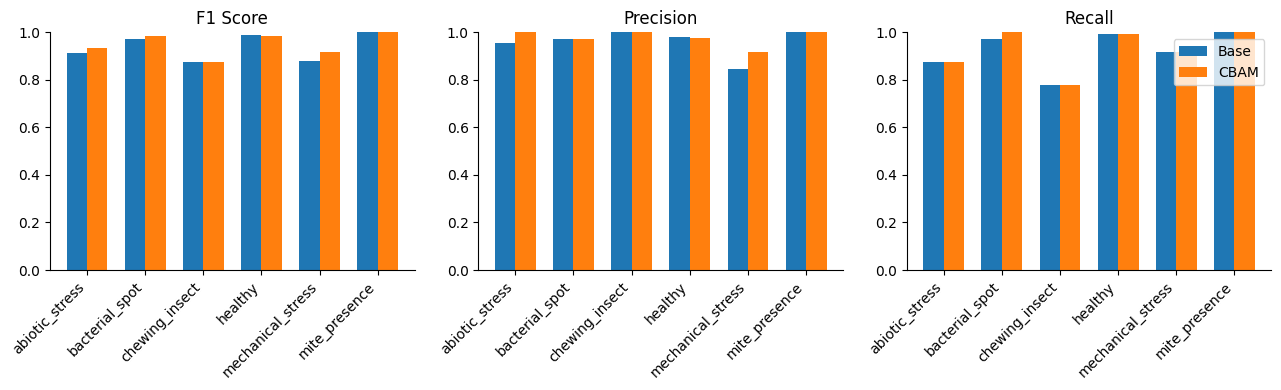


🧠 Evaluando modelo: efficientnetb3

➡️ Variante [BASE]
📏 Usando resolución: (192, 192)
 4/18 ━━━━━━━━━━━━━━━━━━━━ 3s 282ms/step

KeyboardInterrupt: 

In [7]:

# --- 1. CONFIGURACIÓN DE RUTAS ---
output_comparison = OUTPUT_DIR / "cbam_comparisons"
output_comparison.mkdir(parents=True, exist_ok=True)

CSV_METRICS_PATH = Path("./base_models_results/holdout_test_metrics_all_models.csv")

# Solo queremos evaluar estos 3 modelos
TARGET_MODELS = ["mobilenetv3large", "efficientnetb3", "resnet50"]

# Asumimos que MASTER_CLASSES, LOCAL_TEST_PATH y LOCAL_TEST_LABELS 
# ya están definidos del paso de creación del dataset de test.
class_names = CLASSES_PUBLIC
num_classes = len(class_names)

# --- 2. DICCIONARIO DE PREPROCESAMIENTO ---
MODEL_SPECS = {
    "mobilenetv3large": tf.keras.applications.mobilenet_v3.preprocess_input,
    "efficientnetb3": tf.keras.applications.efficientnet.preprocess_input,
    "resnet50": tf.keras.applications.resnet.preprocess_input,
}

# --- 3. EXTRAER TAMAÑOS ÓPTIMOS DEL CSV ---
print("📊 Leyendo tamaños óptimos del CSV...")
if CSV_METRICS_PATH.exists():
    df_results = pd.read_csv(CSV_METRICS_PATH)
    best_img_sizes = {}
    for model_name in TARGET_MODELS:
        model_df = df_results[df_results['model'] == model_name]
        if not model_df.empty:
            best_row = model_df.loc[model_df['f1_macro'].idxmax()]
            best_img_sizes[model_name] = int(best_row['img_size'])
        else:
            print(f"⚠️ No se encontró {model_name} en el CSV. Se usará 224 por defecto.")
            best_img_sizes[model_name] = 224
else:
    print(f"⚠️ Archivo CSV no encontrado en {CSV_METRICS_PATH}. Usando 224x224 para todos.")
    best_img_sizes = {m: 224 for m in TARGET_MODELS}

for m, s in best_img_sizes.items():
    print(f"  - {m}: {s}x{s}")

# --- REQUISITO: Asegúrate de tener importada la función original ---
# from utils import make_dataset 

print("\n🚀 Iniciando evaluación de modelos (Modo Consistente)...")

for model_name in TARGET_MODELS:
    print(f"\n" + "="*40)
    print(f"🧠 Evaluando modelo: {model_name}")
    print(f"="*40)
    
    img_size_val = best_img_sizes[model_name]
    preprocess_fn = MODEL_SPECS[model_name]
    
    # Estructura para guardar las métricas
    model_metrics = {"base": {}, "cbam": {}}
    
    # Rutas de los modelos
    paths = {
        "base": BASE_MODELS_PATH / f"{model_name}_img{img_size_val}_final.keras",
        "cbam": CBAM_MODELS_PATH / f"{model_name}_cbam_best_final.keras"
    }
    
    custom_objects_dict = {"cbam_block": cbam_block, "SpatialPooling": SpatialPooling}

    for variant, path in paths.items():
        print(f"\n➡️ Variante [{variant.upper()}]")
        
        if not path.exists():
            print(f"⚠️ ¡Archivo no encontrado! {path}")
            continue
            
        try:
            # 1. Cargar modelo
            model = load_model(path, compile=False, custom_objects=custom_objects_dict)
            
            # 2. Obtener tamaño exacto de entrada del modelo cargado
            # Esto es vital por si el modelo final tiene un input distinto al esperado
            h, w = model.input_shape[1:3]
            target_size = (h, w) if h is not None else (img_size_val, img_size_val)
            print(f"📏 Usando resolución: {target_size}")

            # 3. CREAR DATASET USANDO LA FUNCIÓN ORIGINAL (make_dataset)
            # Esto asegura que el resize y el preprocesamiento sean IDÉNTICOS al entreno
            eval_ds = make_dataset(
                PUBLIC_TEST_PATH,      # Tus rutas de imágenes
                PUBLIC_TEST_LABELS,    # Tus etiquetas
                target_size[0],        # img_size (asumimos cuadrado)
                preprocess_fn,
                BATCH_SIZE,
                training=False         # ¡IMPORTANTE! training=False desactiva aumentación
            )

            # 4. Predecir
            # Usamos el Dataset directamente en lugar de arrays de numpy
            preds = model.predict(eval_ds, verbose=1)
            y_pred = np.argmax(preds, axis=1)
            
            # Ajustamos y_true por si acaso hubo archivos no leídos en make_dataset 
            # (aunque con strings en lista suele ser directo)
            y_true = np.array(PUBLIC_TEST_LABELS)

            # 5. Calcular métricas
            model_metrics[variant] = {
                "f1": f1_score(y_true, y_pred, average=None, zero_division=0),
                "precision": precision_score(y_true, y_pred, average=None, zero_division=0),
                "recall": recall_score(y_true, y_pred, average=None, zero_division=0)
            }
            
            # Cálculo rápido del F1 Macro para comparar con tu 0.82
            current_f1_macro = f1_score(y_true, y_pred, average='macro')
            print(f"✅ F1 Macro Resultante: {current_f1_macro:.4f}")

        except Exception as e:
            print(f"❌ Error evaluando {variant}: {e}")
            continue
        
    # Imprimir y graficar (tus funciones originales)
    print_metrics_table(model_metrics, model_name, class_names)
    plot_and_save_comparison(model_metrics, model_name, class_names, output_comparison)

print("\n🎉 Evaluación finalizada con el pipeline oficial.")

     



## EVALUATING BEFORE VS AFTER ft

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

# =========================
# Configuración
# =========================
TARGET_DATA_DIR = LOCAL_DATAPATH
TEST_SIZE = 0.2
VAL_SIZE = 0.2
BATCH_SIZE = 16
BASE_SEED = 5681

# Rutas de los modelos
MODELS_DIRS = {
    "Base": {
        "original": Path("./models/Base/final_model"),
        "finetuned": Path("./models/Base_tl/final_model")
    },
    "CBAM": {
        "original": Path("./models/CBAM/final_model"),
        "finetuned": Path("./models/CBAM_tl/final_model")
    }
}

RESULTS_PATH = Path("./comparativa_tl_resultados.csv")

MODELS = [
    "mobilenetv2", "efficientnetb0", "mobilenetv3large", "densenet121",
    "efficientnetb3", "resnet50", "inceptionv3", "resnet101", "vgg16",
    "vgg19", "efficientnetb5"
]
IMAGE_SIZES = [192, 224]
STRATEGIES = ["feature_extractor", "fine_tune_last", "fine_tune_all"]

# Diccionario de preprocesamiento (asegúrate de que coincida con tu código original)
MODEL_SPECS = {
    "mobilenetv2": tf.keras.applications.mobilenet_v2.preprocess_input,
    "efficientnetb0": tf.keras.applications.efficientnet.preprocess_input,
    "mobilenetv3large": tf.keras.applications.mobilenet_v3.preprocess_input,
    "densenet121": tf.keras.applications.densenet.preprocess_input,
    "efficientnetb3": tf.keras.applications.efficientnet.preprocess_input,
    "resnet50": tf.keras.applications.resnet.preprocess_input,
    "inceptionv3": tf.keras.applications.inception_v3.preprocess_input,
    "resnet101": tf.keras.applications.resnet.preprocess_input,
    "vgg16": tf.keras.applications.vgg16.preprocess_input,
    "vgg19": tf.keras.applications.vgg19.preprocess_input,
    "efficientnetb5": tf.keras.applications.efficientnet.preprocess_input,
}

# =========================
# Funciones auxiliares
# =========================
def evaluate_predictions(model, dataset, y_true):
    """Evalúa un modelo y devuelve las métricas."""
    y_prob = model.predict(dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    
    return {
        "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted")),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    }

def get_model_path(base_dir, model_name, img_size, strategy=None, is_finetuned=False):
    """Busca y devuelve la ruta del modelo exacto en el directorio."""
    if is_finetuned:
        path = base_dir / f"{model_name}_img{img_size}_{strategy}.keras"
    else:
        # Los modelos originales terminan en _final.keras o _best_final.keras
        path = base_dir / f"{model_name}_img{img_size}_final.keras"
        if not path.exists():
            path = base_dir / f"{model_name}_best_final.keras"
    return path

# =========================
# Main
# =========================
def main():
    # 1. Cargar datos del nuevo dominio (4 clases) y aislar el TEST SET
    print("Cargando y dividiendo datos...")
    X_target, y_target, class_names = load_paths_and_labels(TARGET_DATA_DIR)
    
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X_target, y_target, test_size=TEST_SIZE, stratify=y_target, random_state=BASE_SEED
    )
    print(f"Set de pruebas aislado: {len(X_test)} muestras.")

    results = []

    # 2. Iterar sobre tipos de arquitectura (Base vs CBAM)
    for model_type, dirs in MODELS_DIRS.items():
        dir_original = dirs["original"]
        dir_finetuned = dirs["finetuned"]
        
        print(f"\n=============================================")
        print(f" EVALUANDO MODELOS TIPO: {model_type}")
        print(f"=============================================")

        # 3. Iterar sobre cada modelo y tamaño de imagen
        for model_name in MODELS:
            if model_type == "CBAM":
                model_name = model_name + "_cbam"
            preprocess_fn = MODEL_SPECS[model_name]
            
            for img_size in IMAGE_SIZES:
                print(f"\n--- {model_type} | {model_name} | img_size={img_size} ---")
                
                # Crear dataset de test para este tamaño y preprocesado
                test_ds = make_dataset(
                    X_test, y_test, img_size, preprocess_fn, BATCH_SIZE, training=False
                )

                # --- A. EVALUACIÓN DEL MODELO ORIGINAL (ANTES) ---
                orig_model_path = get_model_path(dir_original, model_name, img_size, is_finetuned=False)
                
                if not orig_model_path.exists():
                    print(f"Modelo original no encontrado: {orig_model_path.name} -> Saltando.")
                    continue

                tf.keras.backend.clear_session()
                orig_model = tf.keras.models.load_model(orig_model_path, compile=False)
                print("Evaluando modelo original (Zero-Shot)...")
                before_metrics = evaluate_predictions(orig_model, test_ds, y_test)
                
                # --- B. EVALUACIÓN DE LOS MODELOS FINETUNEADOS (DESPUÉS) ---
                # Dado que el 'antes' es el mismo para las 3 estrategias de FT, 
                # evaluamos el original una vez y lo aplicamos a cada estrategia
                for strategy in STRATEGIES:
                    ft_model_path = get_model_path(dir_finetuned, model_name, img_size, strategy, is_finetuned=True)
                    
                    if not ft_model_path.exists():
                        print(f"  Falta modelo FT para estrategia '{strategy}'. Saltando.")
                        continue
                    
                    tf.keras.backend.clear_session()
                    ft_model = tf.keras.models.load_model(ft_model_path, compile=False)
                    print(f"  Evaluando modelo FT ({strategy})...")
                    after_metrics = evaluate_predictions(ft_model, test_ds, y_test)

                    # --- C. COMPILAR FILA DEL CSV ---
                    row = {
                        "model_type": model_type,
                        "model": model_name,
                        "img_size": img_size,
                        "strategy": strategy,
                        "class_compatible": (orig_model.output_shape[-1] == 4), # Debería ser False (6!=4)
                        "base_model_path": str(orig_model_path),
                        "tl_model_path": str(ft_model_path)
                    }

                    # Añadir métricas before, after y delta
                    for metric in before_metrics.keys():
                        row[f"before_{metric}"] = before_metrics[metric]
                        row[f"after_{metric}"] = after_metrics[metric]
                        row[f"delta_{metric}"] = after_metrics[metric] - before_metrics[metric]
                    
                    results.append(row)

    # 4. Guardar resultados
    if results:
        df_results = pd.DataFrame(results)
        # Ordenar columnas lógicamente
        cols_order = ['model_type', 'model', 'img_size', 'strategy', 'class_compatible', 
                      'base_model_path', 'tl_model_path']
        metric_cols = [col for col in df_results.columns if col not in cols_order]
        df_results = df_results[cols_order + metric_cols]
        
        # Ordenar filas por F1_macro del modelo final
        df_results.sort_values(by="after_f1_macro", ascending=False, inplace=True)
        
        df_results.to_csv(RESULTS_PATH, index=False)
        print(f"\n¡Proceso completado! Archivo guardado en: {RESULTS_PATH}")
    else:
        print("\nNo se pudo evaluar ningún modelo. Revisa las rutas.")

if __name__ == "__main__":
    main()

Cargando y dividiendo datos...
Set de pruebas aislado: 37 muestras.

 EVALUANDO MODELOS TIPO: Base

--- Base | mobilenetv2 | img_size=192 ---
Evaluando modelo original (Zero-Shot)...
  Evaluando modelo FT (feature_extractor)...
  Evaluando modelo FT (fine_tune_last)...
  Evaluando modelo FT (fine_tune_all)...

--- Base | mobilenetv2 | img_size=224 ---
Evaluando modelo original (Zero-Shot)...
  Evaluando modelo FT (feature_extractor)...
  Evaluando modelo FT (fine_tune_last)...
  Evaluando modelo FT (fine_tune_all)...

--- Base | efficientnetb0 | img_size=192 ---
Evaluando modelo original (Zero-Shot)...
  Evaluando modelo FT (feature_extractor)...
  Evaluando modelo FT (fine_tune_last)...
  Evaluando modelo FT (fine_tune_all)...

--- Base | efficientnetb0 | img_size=224 ---
Evaluando modelo original (Zero-Shot)...
  Evaluando modelo FT (feature_extractor)...
  Evaluando modelo FT (fine_tune_last)...
  Evaluando modelo FT (fine_tune_all)...

--- Base | mobilenetv3large | img_size=192 ---

KeyError: 'mobilenetv2_cbam'

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# =========================
# Configuración (Asegúrate de importar tus utilidades)
# =========================
# from utils import load_paths_and_labels, make_dataset, SpatialPooling, cbam_block

RESULTS_GAP_PATH = Path("./domain_gap_results.csv")

# [NUEVO] Rutas de los CSVs para leer el mejor tamaño
BASE_MODELS_CSV = Path("./base_models_results/holdout_test_metrics_all_models.csv") 
CBAM_MODELS_CSV = Path("./cbam_models_results/holdout_test_metrics_all_models.csv") 

STRATEGIES = ["feature_extractor", "fine_tune_last", "fine_tune_all"]

# Define qué modelos Base evaluar
MODELS = [
    "mobilenetv2", "efficientnetb0", "mobilenetv3large", "densenet121",
    "efficientnetb3", "resnet50", "inceptionv3", "resnet101", "vgg16",
    "vgg19", "efficientnetb5"
]

# Define qué modelos CBAM evaluar
CBAM_MODELS_TO_INCLUDE = [
    "mobilenetv2", "efficientnetb0", "mobilenetv3large", "densenet121",
    "efficientnetb3", "resnet50", "inceptionv3", "resnet101", "vgg16",
    "vgg19", "efficientnetb5" 
]

IMAGE_SIZES = [192, 224] # [NUEVO] Este será ahora el "tamaño por defecto" si falla el CSV

# =========================
# Funciones
# =========================
def evaluate_f1_macro(model, dataset, y_true):
    y_prob = model.predict(dataset, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))

def get_model_path(base_dir, model_name, img_size, strategy=None, is_finetuned=False, is_cbam=False):
    name_prefix = f"{model_name}_cbam" if is_cbam else model_name
    
    if is_finetuned:
        return base_dir / f"{name_prefix}_img{img_size}_{strategy}.keras"
    else:
        path = base_dir / f"{name_prefix}_img{img_size}_final.keras"
        return path if path.exists() else base_dir / f"{name_prefix}_best_final.keras"
    
def get_best_img_sizes(csv_path, metric="f1_macro"):
    """Lee el CSV y devuelve un diccionario con el tamaño óptimo por modelo."""
    if not csv_path.exists():
        print(f"⚠️ No se encontró {csv_path}. Se evaluarán todos los tamaños por defecto.")
        return {}

    df = pd.read_csv(csv_path)
    
    col_name = 'model' if 'model' in df.columns else 'Model' if 'Model' in df.columns else None
    if not col_name: return {}

    df = df.dropna(subset=[col_name, metric])
    
    best_sizes = {}
    for m_name in df[col_name].unique():
        model_df = df[df[col_name] == m_name]
        best_row = model_df.loc[model_df[metric].idxmax()]
        
        clean_name = str(m_name).lower().replace("_cbam", "")
        best_sizes[clean_name] = int(best_row['img_size'])
        
    return best_sizes

# =========================
# Main
# =========================
def main():
    print("Cargando y aislando conjuntos de TEST...")
    
    X_pub, y_pub, _ = load_paths_and_labels(PUBLIC_DATAPATH)
    _, X_test_pub, _, y_test_pub = train_test_split(
        X_pub, y_pub, test_size=TEST_SIZE, stratify=y_pub, random_state=BASE_SEED
    )
    
    X_loc, y_loc, _ = load_paths_and_labels(LOCAL_DATAPATH)
    _, X_test_loc, _, y_test_loc = train_test_split(
        X_loc, y_loc, test_size=TEST_SIZE, stratify=y_loc, random_state=BASE_SEED
    )

    results = []

    print("Iniciando evaluación de modelos...")
    
    # [NUEVO] Se han añadido las claves "csv_path" a la configuración
    eval_configs = [
        {"models_list": MODELS, "is_cbam": False, "dir_orig": BASE_MODELS_PATH, "dir_ft": TL_BASE_MODELS_PATH, "csv_path": BASE_MODELS_CSV},
        {"models_list": CBAM_MODELS_TO_INCLUDE, "is_cbam": True, "dir_orig": CBAM_MODELS_PATH, "dir_ft": TL_CBAM_MODELS_PATH, "csv_path": CBAM_MODELS_CSV}
    ]
    
    custom_objects = {"SpatialPooling": SpatialPooling, "cbam_block": cbam_block}
    
    for config in eval_configs:
        is_cbam = config["is_cbam"]
        model_type_label = "CBAM" if is_cbam else "Base"
        
        # [NUEVO] Extraer el diccionario de los mejores tamaños antes de evaluar los modelos
        print(f"\nLeyendo tamaños óptimos para modelos {model_type_label}...")
        best_sizes_dict = get_best_img_sizes(config["csv_path"], metric="f1_macro")
        
        for model_name in config["models_list"]:
            if model_name not in MODEL_SPECS: continue
            
            # Desempaquetamos la tupla para coger solo la función de preprocesado
            _, preprocess_fn = MODEL_SPECS[model_name]
            
            display_name = f"{model_name}_cbam" if is_cbam else model_name
            
            # [NUEVO] Decidir qué tamaño(s) vamos a usar para este modelo específico
            if model_name in best_sizes_dict:
                sizes_to_evaluate = [best_sizes_dict[model_name]]
                print(f"✔️ {display_name}: Evaluando solo tamaño óptimo -> {sizes_to_evaluate[0]}x{sizes_to_evaluate[0]}")
            else:
                sizes_to_evaluate = IMAGE_SIZES
                print(f"⚠️ {display_name}: No se halló en CSV. Evaluando -> {sizes_to_evaluate}")
            
            # [MODIFICADO] Ahora iteramos sobre "sizes_to_evaluate" en lugar de "IMAGE_SIZES"
            for img_size in sizes_to_evaluate:
                
                ds_test_pub = make_dataset(X_test_pub, y_test_pub, img_size, preprocess_fn, BATCH_SIZE, training=False)
                ds_test_loc = make_dataset(X_test_loc, y_test_loc, img_size, preprocess_fn, BATCH_SIZE, training=False)
                
                # Evaluar original (Before FT)
                orig_path = get_model_path(config["dir_orig"], model_name, img_size, is_finetuned=False, is_cbam=is_cbam)
                if not orig_path.exists():
                    print(f"  -> No encontrado: {orig_path.name}")
                    continue
                
                tf.keras.backend.clear_session()
                orig_model = tf.keras.models.load_model(orig_path, compile=False, custom_objects=custom_objects)
                f1_pub_before = evaluate_f1_macro(orig_model, ds_test_pub, y_test_pub)
                f1_loc_before = evaluate_f1_macro(orig_model, ds_test_loc, y_test_loc)
                
                # Evaluar estrategias FT (After FT)
                for strategy in STRATEGIES:
                    ft_path = get_model_path(config["dir_ft"], model_name, img_size, strategy, is_finetuned=True, is_cbam=is_cbam)
                    if not ft_path.exists(): continue
                    
                    tf.keras.backend.clear_session()
                    ft_model = tf.keras.models.load_model(ft_path, compile=False, custom_objects=custom_objects)
                    f1_pub_after = evaluate_f1_macro(ft_model, ds_test_pub, y_test_pub)
                    f1_loc_after = evaluate_f1_macro(ft_model, ds_test_loc, y_test_loc)
                    
                    results.append({
                        "Model": display_name, 
                        "Model_Type": model_type_label,
                        "img_size": img_size,
                        "strategy": strategy,
                        "F1_Public_before": f1_pub_before,
                        "F1_Local_before": f1_loc_before,
                        "F1_Public_after": f1_pub_after,
                        "F1_Local_after": f1_loc_after
                    })

    df = pd.DataFrame(results)
    if df.empty:
        print("No se generaron resultados. Verifica las rutas de los modelos.")
        return
        
    df.to_csv(RESULTS_GAP_PATH, index=False)
    print(f"\nResultados guardados en {RESULTS_GAP_PATH}")

    # =========================
    # 3. GENERACIÓN DE LA GRÁFICA
    # =========================
    print("Generando gráfica...")
    
    df_best = df.sort_values("F1_Local_after", ascending=False).groupby("Model").head(1).copy()

    def format_plot_name(name):
        if name.endswith("_cbam"):
            base = name.replace("_cbam", "").capitalize()
            return f"{base} (CBAM)"
        return name.capitalize()

    df_best["Model_Plot"] = df_best["Model"].apply(format_plot_name)

    df_best["DeltaF1_Before"] = df_best["F1_Public_before"] - df_best["F1_Local_before"]
    df_best["DeltaF1_After"]  = df_best["F1_Public_after"] - df_best["F1_Local_after"]

    df_plot = pd.melt(
        df_best,
        id_vars=["Model_Plot"],
        value_vars=["DeltaF1_Before", "DeltaF1_After"],
        var_name="Condition",
        value_name="DeltaF1"
    )

    df_plot["Condition"] = df_plot["Condition"].replace({
        "DeltaF1_Before": "Before FT",
        "DeltaF1_After": "After FT"
    })

    sns.set_theme(style="whitegrid", font_scale=1.1) 
    plt.figure(figsize=(16, 7)) 
    palette = sns.color_palette("viridis", 2)

    ax = sns.barplot(
        data=df_plot,
        x="Model_Plot", y="DeltaF1", hue="Condition",
        palette=palette, edgecolor="black", linewidth=1.1
    )

    plt.xticks(rotation=45, ha="right") 
    plt.ylabel("ΔF1 (Public - Local)")
    plt.xlabel("")

    plt.axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.7)

    offset = 0.01 
    
    for p in ax.patches:
        height = p.get_height()
        if abs(height) < 1e-6:
            continue
        
        y_pos = height + offset if height >= 0 else height - offset
        va_align = 'bottom' if height >= 0 else 'top'

        ax.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2, y_pos),
            ha='center',
            va=va_align,
            fontsize=9, 
            rotation=90
        )

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()

Cargando y aislando conjuntos de TEST...
Iniciando evaluación de modelos...

Leyendo tamaños óptimos para modelos Base...
✔️ mobilenetv2: Evaluando solo tamaño óptimo -> 192x192

✔️ efficientnetb0: Evaluando solo tamaño óptimo -> 192x192
✔️ mobilenetv3large: Evaluando solo tamaño óptimo -> 192x192
✔️ densenet121: Evaluando solo tamaño óptimo -> 224x224
